# An Elastically Supported Rod

## Part 1: A modification to the PDE: continuous elastic support

In the book, the finite element derivation and implementation of rod extension (the 1D Poisson equation) is presented. In this workshop, you are asked to do the same for a slightly different problem.

![](https://github.com/TUDelft-MUDE/source-files/raw/main/file/barDefinition-2.png)

For this exercise we consider an elastically supported rod. An example of this would be a foundation pile in soil. The equilibrium of an elastically supported rod can be described with the following differential equation:

$$ -EA \frac{\partial^2 u}{\partial x^2} + ku = q $$

where $EA$ is the axial stiffness of the rod, $u(x)$ is the unknown displacement, $k$ is the stiffness of the elastic support and $q$ is a distributed load. We consider a case with Dirichlet boundary condition at $x=0$ and a Neumann boundary condition at $x=L$.

$$
u = 0, \quad \text{at} \quad x = 0 \\
EA\frac{\partial u}{{\partial x}} = F, \quad \text{at} \quad x = L
$$

This differential equation is the inhomogeneous Helmholtz equation, which also has applications in dynamics and electromagnetics. 

The finite element discretized version of this PDE can be obtained following the same steps as shown for the unsupported rod in the book. The additional term with respect to the case without elastic support is the second term on the left hand side: $ku$. Using Neumann boundary condition (i.e. an applied load) at $x=L$, the following expression is found for the discretized form:

$$\left[\int \mathbf{B}^T EA \mathbf{B} + \mathbf{N}^T k \mathbf{N} \,dx\right]\mathbf{u} = \int \mathbf{N}^T q \,d x + \mathbf{N}^T F \Bigg|_{x=L} $$

> **Task 1.1: Derive the discrete form:**
>
> Derive the discrete form of the PDE given above. You can follow the same steps as in the book for the term with $EA$ and the right hand side, but now carrying along the additional term $ku$ from the PDE. Note that there are no derivatives in this term $ku$ which means that integration by parts does not need to be applied on it. Show that this term leads to the $\int\mathbf{N}^Tk\mathbf{N}\,dx$ term in the $\mathbf{K}$-matrix.

## Part 2: Modification to the FE implementation

The only change with respect to the procedure as implemented in the book is the formulation of the $\mathbf{K}$-matrix, which now consists of two terms:

$$ \mathbf{K} = \int \mathbf{B}^TEA\mathbf{B} + \mathbf{N}^Tk\mathbf{N}\,dx $$

To calculate the integral exactly we must use two integration points.

$$ \mathbf{K_e} = \sum_{i=1}^{n_\mathrm{ip}} \left(\mathbf{B}^T(x_i)EA\mathbf{B}(x_i) + \mathbf{N}^T(x_i) k\mathbf{N}(x_i) \right) w_i$$

> **Task 2.1: Code implementation:**
>
> The only change needed with respect to the implementation of the book is in the calculation of the element stiffness matrix. Copy the code from the book and add the term related to the distributed support in the right position.
>
> Remarks:
>
> - The function evaluate_N is already present in the code in the book
> - The get_element_matrix function already included a loop over two integration points
> - You need to define $k$ somewhere. To allow for varying $k$ as required below, it is convenient to make $k$ an additional argument of the simulate function and pass it on to lower level functions from there (cf. how $EA$ is passed on)

In [32]:
import numpy as np
import matplotlib.pyplot as plt

In [33]:
# Returns the evaluated N matrix
# - The local coordinate of evaluation "x_local"
# - The element size "dx"
def evaluate_N(x_local, dx):
    return np.array([[1-x_local/dx, x_local/dx]])

# Returns the evaluated B vector
# - The local coordinate of evaluation "x_local"
# - The element size "dx"
def evaluate_B(x_local, dx):
    return np.array([[-1/dx, 1/dx]])

# Returning the matrix of a single element
# - The stiffness of the rod "EA"
# - The distributed support stiffness "k"
# - The length of an element "dx"
def get_element_matrix(EA, k, dx):
    integration_locations = [(dx - dx/(3**0.5))/2,
                             (dx + dx/(3**0.5))/2]
    integration_weights = [dx/2, dx/2]

    n_node = 2
    K_loc = np.zeros((n_node, n_node))

    for x_i, w_i in zip(integration_locations, integration_weights):
        B = evaluate_B(x_i, dx)
        N = evaluate_N(x_i, dx)
        K_loc += (EA * B.T @ B + k * N.T @ N) * w_i

    return K_loc

# Returning the force vector of a single element (distributed load only)
# - The magnitude of constant distributed load "q"
# - The length of the element "dx"
def get_element_force(q, dx):
    n_node = 2
    integration_locations = [(dx - dx/(3**0.5))/2,
                             (dx + dx/(3**0.5))/2]
    integration_weights = [dx/2, dx/2]

    f_loc = np.zeros(n_node)

    for x_i, w_i in zip(integration_locations, integration_weights):
        N = evaluate_N(x_i, dx)
        f_loc += N.squeeze() * q * w_i

    return f_loc


> **Task 2.2: Analyze the influence of $k$ on the results:**
>
> Use the following parameters: $L=3\text{ m}$, $EA=1000\text{ N}$, $F=10\text{ N}$, $q=0 \text{ N/m}$ (all values are the same as in the book, except for $q$). Additionally, use $k=1000$ N/m2 and a discretization of 10 elements.
>
> Check the influence of the distributed support on the solution:
>
> - First use $q=0$ N/m and $k=1000$ N/m2
> - Then set $k$ to zero and compare the results
> - Does the influence of the distributed support on the solution make sense? 
> 
> Note to Civil Engineering students: you have seen this differential equation in CIEM0000 and solved it analytically. Do you recall the analytical solution and does the numerical solution look similar to what you would expect? 

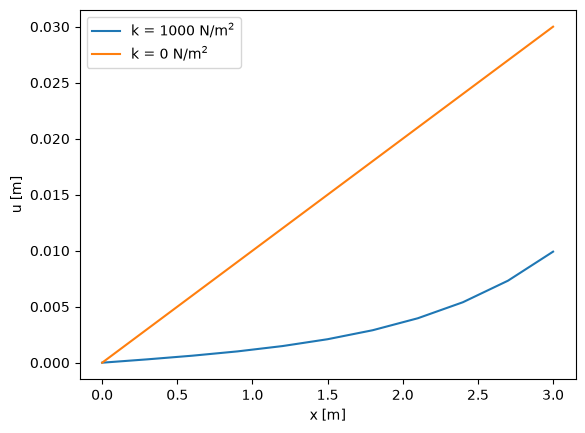

In [ ]:
# Use the simulate function to get displacements.
def simulate(n_element,    # number of elements
             length=3,     # length of the domain
             EA=1e3,       # axial stiffness
             F_right=10,   # load applied at x=L
             q_load=0,     # distributed load
             k=1e3         # distributed support stiffness
    ):
    n_node = n_element + 1
    dx = length / n_element
    x = np.linspace(0, length, n_node)

    K = np.zeros((n_node, n_node))
    f = np.zeros(n_node)

    for element in range(n_element):
        nodes = [element, element + 1]
        K_local = get_element_matrix(EA, k, dx)
        f_local = get_element_force(q_load, dx)
        K[np.ix_(nodes, nodes)] += K_local
        f[nodes] += f_local

    f[-1] += F_right

    u = np.zeros(n_node)
    u[1:] = np.linalg.solve(K[1:, 1:], f[1:])

    return x, u

# Plot u versus x for k = 1000 and k = 0.
plt.figure()
for k_value in (1000, 0):
    x, u = simulate(10, k=k_value)
    plt.plot(x, u, label=f'k = {k_value:g} N/m$^2$')
plt.xlabel('x [m]')
plt.ylabel('u [m]')
plt.legend()


> **Task 2.3: Investigate the influence of discretization on the quality of the solution:**
>
> - How many elements do you need to get a good solution with $k=1000$ N/m?
> - How about when the stiffness of the distributed support is increased to $k=10^6$ N/m2 ?
>
> Simulate and plot results for different numbers of elements for each of the above questions.

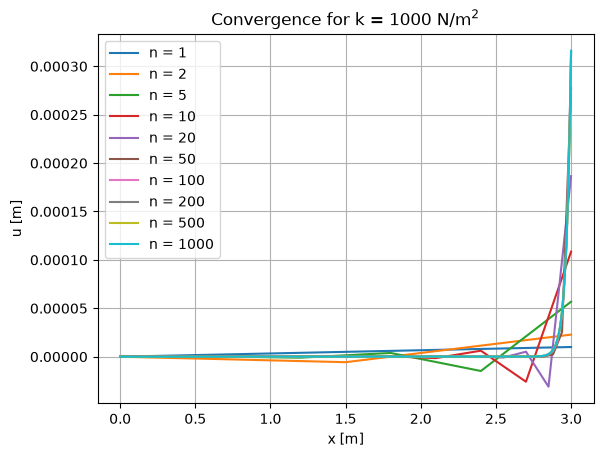

In [34]:
element_counts = [1, 2, 5, 10, 20, 50, 100, 200, 500, 1000]

plt.figure()
for n_element in element_counts:
    x, u = simulate(n_element, k=1000000)
    plt.plot(x, u, label=f'n = {n_element}')

plt.xlabel('x [m]')
plt.ylabel('u [m]')
plt.title('Convergence for k = 1000 N/m$^2$')
plt.legend()
plt.grid(True)


## Part 3: Change boundary condition

Now suppose the end of the rod at $x=L$ is loaded not by a force but by a prescribed displacement. What do you need to change to the `simulate` function to achieve this? Hint: look at the box **Eliminiation of Dirichlet boundary conditions** on the [Finite element implementation](https://mude.citg.tudelft.nl/book/2025/fem/matrix.html#boundary-conditions) page in the book for a description of how to deal with inhomogeneous Dirichlet boundary conditions in a more general case.

> **Task 3.1: Implement changes required to prescribe $u(L)$**
> - Code the `simulate_new` function below such that a nonzero Dirichlet boundary condition is applied at $x=L$ instead of a force
> - Perform the simulation with the same parameters as before and $k=1000$ and $u_\mathrm{right}=0.01$ m.
> - Compare the obtained field $u(x)$ to that from task 2.2.

End displacement with force: 0.009915 m
Prescribed end displacement: 0.010000 m
Maximum difference between fields: 8.545386e-05 m


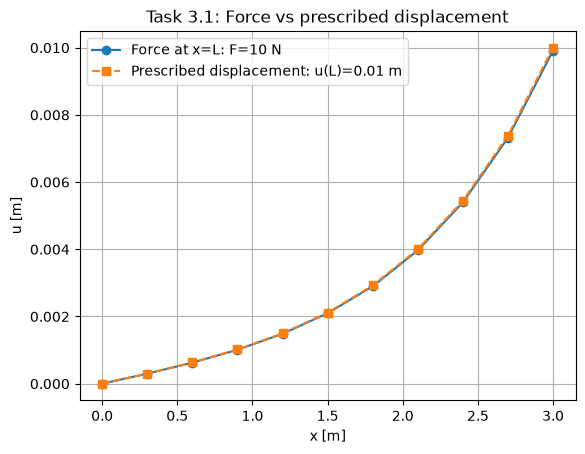

In [36]:
def simulate_new(n_element,
                 length=3,
                 EA=1e3,
                 k=1000,
                 u_right=0.01,
                 q_load=0):
    dx = length / n_element
    n_node = n_element + 1
    x = np.linspace(0, length, n_node)

    K_global = np.zeros((n_node, n_node))
    f_global = np.zeros(n_node)

    for element in range(n_element):
        nodes = [element, element + 1]
        K_local = get_element_matrix(EA, k, dx)
        f_local = get_element_force(q_load, dx)
        K_global[np.ix_(nodes, nodes)] += K_local
        f_global[nodes] += f_local

    fixed = np.array([0, n_node - 1])
    free = np.arange(1, n_node - 1)
    u = np.zeros(n_node)
    u[-1] = u_right

    if free.size:
        rhs = f_global[free] - K_global[np.ix_(free, fixed)] @ u[fixed]
        u[free] = np.linalg.solve(K_global[np.ix_(free, free)], rhs)

    return x, u

n_element = 10
parameters = dict(length=3, EA=1e3, k=1e3, q_load=0)

# Compare the force boundary condition from Task 2.2 with prescribed u(L).
x_force, u_force = simulate(n_element, F_right=10, **parameters)
x_displacement, u_displacement = simulate_new(
    n_element, u_right=0.01, **parameters
)

plt.figure()
plt.plot(x_force, u_force, 'o-', label='Force at x=L: F=10 N')
plt.plot(x_displacement, u_displacement, 's--',
         label='Prescribed displacement: u(L)=0.01 m')
plt.xlabel('x [m]')
plt.ylabel('u [m]')
plt.title('Task 3.1: Force vs prescribed displacement')
plt.legend()
plt.grid(True)

print(f'End displacement with force: {u_force[-1]:.6f} m')
print(f'Prescribed end displacement: {u_displacement[-1]:.6f} m')
print(f'Maximum difference between fields: '
      f'{np.max(np.abs(u_force - u_displacement)):.6e} m')


With $k=1000\,\mathrm{N/m^2}$, the force-loaded solution ends at $u(L)=0.009915\,\mathrm{m}$, while the prescribed-displacement solution ends at exactly $0.01\,\mathrm{m}$. The maximum difference between the nodal fields is approximately $8.55\times10^{-5}\,\mathrm{m}$, so the plotted curves nearly overlap. This is expected because the 10 N force in Task 2.2 produces an end displacement very close to the prescribed value.

In [ ]:
# Use the simulate function to get displacements.
def simulate(n_element,    # number of elements
             length=3,     # length of the domain
             EA=1e3,       # axial stiffness
             F_right=10,   # load applied at x=L
             q_load=0,     # distributed load
             k=1e3         # distributed support stiffness
    ):
    n_node = n_element + 1
    dx = length / n_element
    x = np.linspace(0, length, n_node)

    K = np.zeros((n_node, n_node))
    f = np.zeros(n_node)

    for element in range(n_element):
        nodes = [element, element + 1]
        K_local = get_element_matrix(EA, k, dx)
        f_local = get_element_force(q_load, dx)
        K[np.ix_(nodes, nodes)] += K_local
        f[nodes] += f_local

    f[-1] += F_right

    u = np.zeros(n_node)
    u[1:] = np.linalg.solve(K[1:, 1:], f[1:])

    return x, u

# Plot u versus x for k = 1000 and k = 0.
plt.figure()
for k_value in (1000, 0):
    x, u = simulate(10, k=k_value)
    plt.plot(x, u, label=f'k = {k_value:g} N/m$^2$')
plt.xlabel('x [m]')
plt.ylabel('u [m]')
plt.legend()

In [40]:
import numpy as np
import scipy.sparse as sp

I = np.eye(5)
I_csr = sp.csr_array(I)

I_csr_mod = I_csr.copy()
I_csr_mod[2, :] = 0.0   

I_csr_alt = I_csr.copy()
start, end = I_csr_alt.indptr[2], I_csr_alt.indptr[3]   # beginning and end of row 2
I_csr_alt.indices[start:end] = 0.0

I_lil = I_csr.copy().tolil()
I_lil[2, :] = 0.0   
I_csr_lil = I_lil.tocsr()

print(I_csr)
print(I)
print('Size of I_csr:', I_csr.size)
print('Size of I_csr_mod:', I_csr_mod.size)
print('Size of I_csr_alt:', I_csr_alt.size)
print('Size of I_csr_lil:', I_csr_lil.size)

<Compressed Sparse Row sparse array of dtype 'float64'
	with 5 stored elements and shape (5, 5)>
  Coords	Values
  (0, 0)	1.0
  (1, 1)	1.0
  (2, 2)	1.0
  (3, 3)	1.0
  (4, 4)	1.0
[[1. 0. 0. 0. 0.]
 [0. 1. 0. 0. 0.]
 [0. 0. 1. 0. 0.]
 [0. 0. 0. 1. 0.]
 [0. 0. 0. 0. 1.]]
Size of I_csr: 5
Size of I_csr_mod: 9
Size of I_csr_alt: 5
Size of I_csr_lil: 4


> By Frans van der Meer, Delft University of Technology. CC BY 4.0, more info on the Credits page of Workbook. 